# Classify spikes using DTW

In [1]:
DATA_DIR = 'C:/Datasets/raap/invitro/juxta'

CUT_PARAMS = {
    'signal_name': 'wideband',
    'event_name': 'spk',
    'cut_window': [-0.001, 0.002],
    'fs': 40000
}
SMOOTH_PARAMS = {
    'window_length': 9,
    'polyorder': 3
}

In [2]:
cell_names = [
    '2406241PZ_01',
    '2406263PZ_01',
    '2406282PZ_01',
    '2407031PZ_01',
    '2407031SI_gr2',
    '2407041SI_gr1'
]

In [3]:
from classifiy_spikes_using_dtw import load_training_data
training_data = load_training_data(
    cell_names,
    DATA_DIR,
    cut_params=CUT_PARAMS,
)

In [4]:
from classifiy_spikes_using_dtw import preprocess_shapes
processed = []
for shapes in training_data:
    processed.append(
        tuple([preprocess_shapes(s, SMOOTH_PARAMS, 0.1) for s in shapes])
    )

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from classifiy_spikes_using_dtw import average_shapes

cells_means = [
    tuple([
        average_shapes(shapes, dv_threshold=0.1)
        for shapes in cell_shapes
    ]) for cell_shapes in processed
]

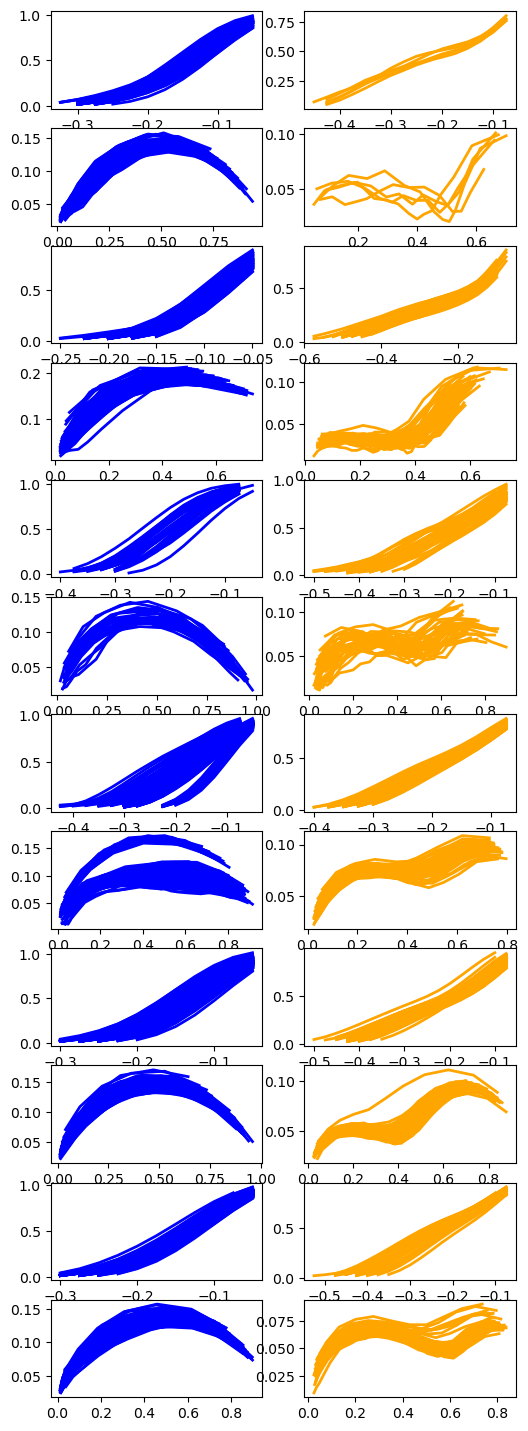

In [6]:
fig, axes = plt.subplots(len(processed) * 2, 2, figsize=(6, 3 * len(processed)))
for i, proc_shapes in enumerate(processed):
    for j, (shapes, color) in enumerate(zip(proc_shapes, ['blue', 'orange'])):
        for shape in shapes:
            ax = axes[i * 2][j]
            ax.plot(
                shape.get_rising(0.15, 0.85).times,
                shape.get_rising(0.15, 0.85).values,
                color=color,
                linewidth=2
            )
            ax = axes[i * 2 + 1][j]
            ax.plot(
                shape.get_rising(0.15, 0.85).values[:-1],
                np.diff(shape.get_rising(0.15, 0.85).values),
                color=color,
                linewidth=2
            )
plt.show()

In [7]:
pool_spikes = [
    (shape, label)
    for cell_shapes in processed
    for label, shapes in enumerate(cell_shapes)
    for shape in shapes
]
pool_shapes = [shape for shape, _ in pool_spikes]
y = np.array([label for _, label in pool_spikes])

In [8]:
from tqdm import tqdm
from dtw import dtw

D = np.zeros((len(pool_spikes), len(pool_spikes)))
for i, shape_1 in tqdm(enumerate(pool_shapes), total=len(pool_shapes)):
    for j, shape_2 in enumerate(pool_shapes):
        if i == j:
            D[i][j] = 0
            continue
        phase_1 = np.stack([
            shape_1.get_rising(0.15, 0.85).values[:-1],
            np.diff(shape_1.get_rising(0.15, 0.85).values)
        ], axis=1)
        phase_2 = np.stack([
            shape_2.get_rising(0.15, 0.85).values[:-1],
            np.diff(shape_2.get_rising(0.15, 0.85).values)
        ], axis=1)

        alignment = dtw(
            phase_1,
            phase_2,
            dist_method='euclidean'
        )
        D[i][j] = getattr(alignment, 'distance')
        D[j][i] = D[i][j]

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.



100%|██████████| 1247/1247 [04:55<00:00,  4.22it/s]


In [9]:
sort_idx = np.argsort(y)

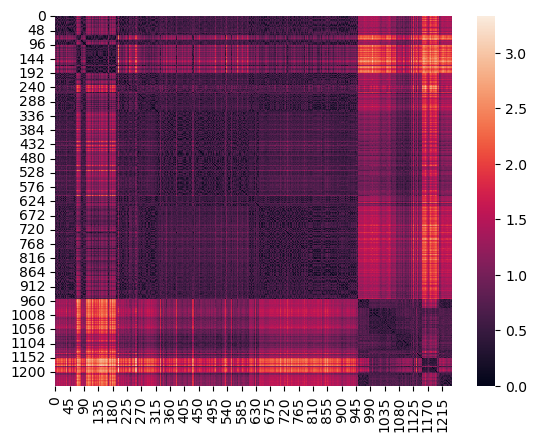

In [10]:
import seaborn as sns
sns.heatmap(D[sort_idx][:, sort_idx])
plt.show()

In [11]:
import heapq
k = 5
pred_y = []
pred_proba = []
mean_dist = []
for i in range(len(pool_spikes)):
    D_i = D[i]
    D_i[i] = 0
    heap = [(D_i[j], y[j]) for j in range(len(pool_spikes)) if j != i]
    neighbors = heapq.nsmallest(k, heap)
    neighbor_labels = [label for _, label in neighbors]
    pred_proba.append(np.mean(neighbor_labels))
    mean_dist.append(np.mean([dist for dist, _ in neighbors]))
    pred_y.append(int(np.round(pred_proba[-1])))
pred_y = np.array(pred_y)
pred_proba = np.array(pred_proba)
miss_id = np.where(pred_y != y)[0]


In [12]:
np.mean(pred_y == y)

np.float64(0.9943865276663993)

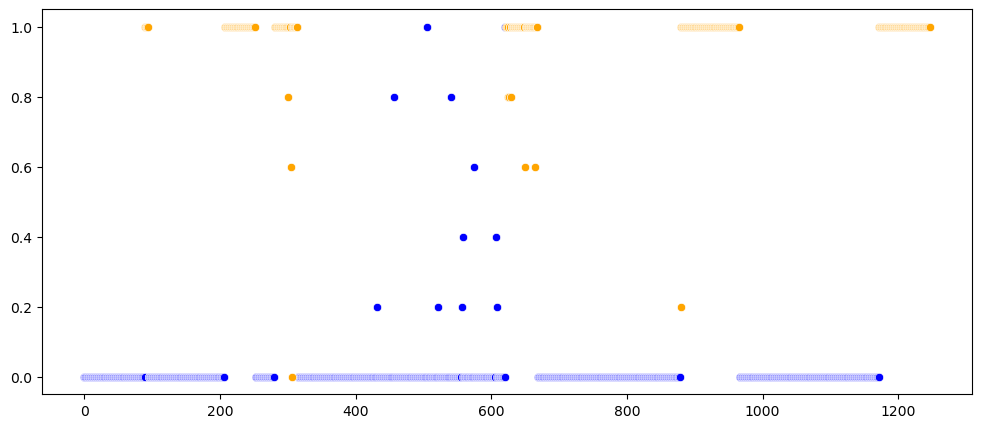

In [13]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 1, figsize=(12, 5))
for label, color in zip([0, 1], ['blue', 'orange']):
    sns.scatterplot(
        x=np.where(y == label)[0],
        y=pred_proba[y == label],
        color=color,
        ax=ax
    )
plt.show()

c:\Users\g\anaconda3\envs\juxta\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
c:\Users\g\anaconda3\envs\juxta\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


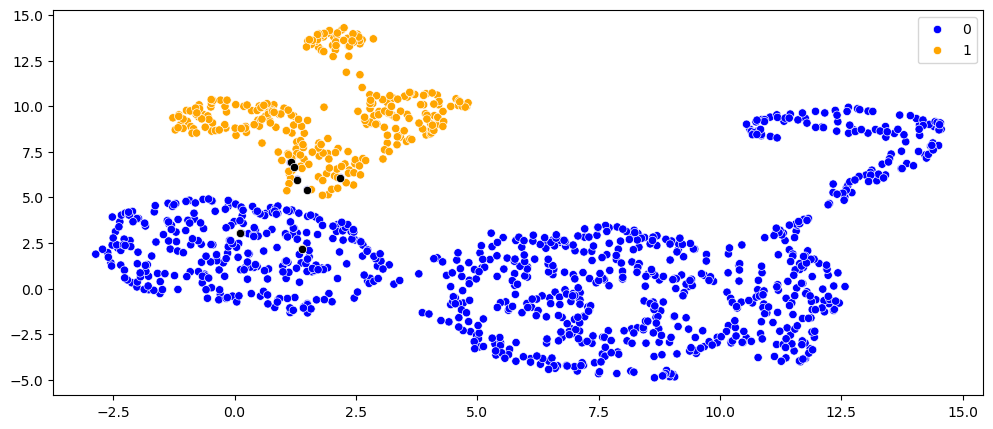

In [14]:
import umap
reducer = umap.UMAP(
    n_components=2,
    random_state=42,
    metric='precomputed',
    min_dist=0.5,
)
X_reduced = reducer.fit_transform(D)
fig, ax = plt.subplots(1, 1, figsize=(12, 5))
sns.scatterplot(
    x=X_reduced[:, 0],
    y=X_reduced[:, 1],
    hue=y,
    palette=['blue', 'orange'],
    ax=ax
)
sns.scatterplot(
    x=X_reduced[miss_id, 0],
    y=X_reduced[miss_id, 1],
    color='black',
    ax=ax
)
plt.show()